In [1]:
import sys
from pathlib import Path

CODE_ROOT = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline")
for folder in ["", "scripts", "pre_processing", "feature_extraction", "post_processing"]:
    if str(CODE_ROOT / folder) not in sys.path:
        sys.path.insert(0, str(CODE_ROOT / folder))

from pathlib import Path
import json
import os
import re
import numpy as np
import yaml
from pathlib import Path
import pandas as pd

import gzip
import struct
import math

import SimpleITK as sitk
import time

from scipy import ndimage
import matplotlib.pyplot as plt

from scripts import *
from visualize import *
from n4 import *
from timer import *

In [2]:
import yaml
config_path = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/config_files/setup.yaml")

with open(config_path, "r") as f:
    config = yaml.safe_load(f)

config

{'DATA_ROOT': '/Users/kamleshranabhat/Desktop/radiomics/dataset',
 'IMAGES_DIR': '/Users/kamleshranabhat/Desktop/radiomics/dataset/imagesTr',
 'LABELS_DIR': '/Users/kamleshranabhat/Desktop/radiomics/dataset/labelTr',
 'PROJECT_ROOT': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline',
 'CODEBASE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline',
 'OUTPUT_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs',
 'MASK_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/masks',
 'FEATURE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/features',
 'TABLE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/tables',
 'FIGURE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures',
 'REGISTRATION_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/registration',
 'BIAS_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/bias_correction',
 'REP

# Validation with a known bias field

1. Take channel 0 of BreastMRI018 and correct it with N4. This gives an image with (almost) no bias: the
   "clean" image.
2. Multiply it by a known smooth field: a 3D gradient that brightens the image by up to ±30 % from one
   side to the other and top to bottom.
3. Run N4 on the result and compare the recovered field with the known one inside the body.

A bias field is only defined up to a constant factor (a uniformly brighter image looks the same after
normalization), so both fields are divided by their mean inside the body before comparing.

In [3]:
case = "BreastMRI018"
raw = load_image(image_path(case, 0), sitk.sitkFloat32)
with Timer() as t:
    clean, _ = n4_bias_field_correction(raw)
print("N4 on a %s image: %.1f s" % ("x".join(map(str, raw.GetSize())), t.seconds))

# known multiplicative field: linear in x and z, +-30 % across the field of view
z, y, x = np.meshgrid(*[np.linspace(-1, 1, n) for n in raw.GetSize()[::-1]], indexing="ij")
known_field = (1.0 + 0.3 * x) * (1.0 + 0.15 * z)
biased = image_from_array((array_from_image(clean) * known_field).astype(np.float32), raw)

with Timer() as t:
    _, recovered = n4_bias_field_correction(biased)
body = array_from_image(body_mask(raw)) > 0
known = known_field[body] / known_field[body].mean()
found = array_from_image(recovered)[body]
found = found / found.mean()
print("N4 on the artificially biased image: %.1f s" % t.seconds)
print("known field range in body   : %.2f .. %.2f" % (known.min(), known.max()))
print("recovered field range       : %.2f .. %.2f" % (found.min(), found.max()))
print("correlation known vs found  : %.3f" % np.corrcoef(known, found)[0, 1])
print("median |relative error|     : %.1f %%" % (100 * np.median(np.abs(found / known - 1))))

Time taken: 3.6720430850982666 seconds
N4 on a 448x448x208 image: 3.7 s
Time taken: 2.9730679988861084 seconds
N4 on the artificially biased image: 3.0 s
known field range in body   : 0.58 .. 1.40
recovered field range       : 0.86 .. 1.10
correlation known vs found  : 0.714
median |relative error|     : 9.0 %


In [4]:
case = "BreastMRI018"
raw = load_image(image_path(case, 0), sitk.sitkFloat32)
with Timer() as t:
    clean, _ = n4_bias_field_correction(raw)
print("N4 on a %s image: %.1f s" % ("x".join(map(str, raw.GetSize())), t.seconds))

# known multiplicative field: linear in x and z, +-30 % across the field of view
z, y, x = np.meshgrid(*[np.linspace(-1, 1, n) for n in raw.GetSize()[::-1]], indexing="ij")
known_field = (1.0 + 0.3 * x) * (1.0 + 0.15 * z)
biased = image_from_array((array_from_image(clean) * known_field).astype(np.float32), raw)

with Timer() as t:
    _, recovered = n4_bias_field_correction(biased)
body = array_from_image(body_mask(raw)) > 0
known = known_field[body] / known_field[body].mean()
found = array_from_image(recovered)[body]
found = found / found.mean()
print("N4 on the artificially biased image: %.1f s" % t.seconds)
print("known field range in body   : %.2f .. %.2f" % (known.min(), known.max()))
print("recovered field range       : %.2f .. %.2f" % (found.min(), found.max()))
print("correlation known vs found  : %.3f" % np.corrcoef(known, found)[0, 1])
print("median |relative error|     : %.1f %%" % (100 * np.median(np.abs(found / known - 1))))

Time taken: 3.1937239170074463 seconds
N4 on a 448x448x208 image: 3.2 s
Time taken: 3.7138290405273438 seconds
N4 on the artificially biased image: 3.7 s
known field range in body   : 0.58 .. 1.40
recovered field range       : 0.86 .. 1.10
correlation known vs found  : 0.714
median |relative error|     : 9.0 %


In [5]:
def n4_field(image, shrink_factor, fitting_levels, iterations, convergence_threshold):
    """Bias field b (array) with explicit N4 settings - for the settings comparison only."""
    log_bias = estimate_log_bias_field(image, shrink_factor=shrink_factor, fitting_levels=fitting_levels,
                                       iterations=iterations, convergence_threshold=convergence_threshold)
    return np.exp(array_from_image(log_bias))


rows = []
for shrink_factor, levels, iterations, threshold in [(4, 3, 50, 1e-3), (4, 1, 300, 0.0), (4, 2, 200, 0.0),
                                                     (4, 4, 100, 0.0)]:
    with Timer() as t:
        field = n4_field(biased, shrink_factor, levels, iterations, threshold)
    found = field[body] / field[body].mean()
    rows.append({"shrink": shrink_factor, "levels": levels, "iterations/level": iterations,
                 "convergence": threshold, "seconds": t.seconds,
                 "corr_with_known": np.corrcoef(known, found)[0, 1],
                 "recovered_min": found.min(), "recovered_max": found.max(),
                 "median_rel_error_%": 100 * np.median(np.abs(found / known - 1))})
display(pd.DataFrame(rows).round(3))

Time taken: 3.000209093093872 seconds
Time taken: 13.680907011032104 seconds
Time taken: 17.23763680458069 seconds
Time taken: 17.307910919189453 seconds


,shrink,levels,iterations/level,convergence,seconds,corr_with_known,recovered_min,recovered_max,median_rel_error_%
0,4,3,50,0.001,3.000,0.714,0.856,1.104,9.037
1,4,1,300,0.000,13.681,0.790,0.797,1.098,8.604
2,4,2,200,0.000,17.238,0.682,0.744,1.121,8.776
3,4,4,100,0.000,17.308,0.516,0.678,1.791,9.457


In [6]:
rows = []
bias_examples = {}
with Timer() as t:
    for case in list_case():
        left = array_from_image(load_image(mask_path(case, "L"))) > 0
        right = array_from_image(load_image(mask_path(case, "R"))) > 0
        roi = left | right
        for channel in range(int(config["N_CHANNELS"])):
            image = load_image(image_path(case, channel))
            log_bias = estimate_log_bias_field(image)
            field = np.exp(array_from_image(log_bias))
            field_roi = field[roi] / field[roi].mean()
            rows.append({"case": case, "channel": channel,
                         "bias_p5": np.percentile(field_roi, 5), "bias_p95": np.percentile(field_roi, 95),
                         "spread_%": 100 * (np.percentile(field_roi, 95) - np.percentile(field_roi, 5)),
                         "L_over_R": field[left].mean() / field[right].mean()})
            if channel == 0:
                bias_examples[case] = field
bias_table = pd.DataFrame(rows)
bias_table.to_csv(Path(config["TABLE_DIR"]) / "bias_field_summary.csv", index=False)
print("20 N4 runs in %.0f s" % t.seconds)
display(bias_table.round(3))
print("median spread inside the ROIs: %.1f %% (range %.1f - %.1f %%)"
      % (bias_table["spread_%"].median(), bias_table["spread_%"].min(), bias_table["spread_%"].max()))

Time taken: 56.36145877838135 seconds
20 N4 runs in 56 s


,case,channel,bias_p5,bias_p95,spread_%,L_over_R
0,BreastMRI002,0,0.922,1.060,13.741000,1.025
1,BreastMRI002,1,0.926,1.054,12.757000,1.024
2,BreastMRI002,2,0.831,1.166,33.521000,1.005
3,BreastMRI002,3,0.926,1.059,13.321000,1.022
4,BreastMRI006,0,0.974,1.024,5.035000,0.986
5,BreastMRI006,1,0.897,1.118,22.086000,0.954
6,BreastMRI006,2,0.975,1.024,4.927000,0.984
7,BreastMRI006,3,0.978,1.022,4.328000,0.987
8,BreastMRI018,0,0.946,1.054,10.780000,1.011
9,BreastMRI018,1,0.960,1.040,8.031000,1.006


median spread inside the ROIs: 9.0 % (range 0.9 - 33.5 %)


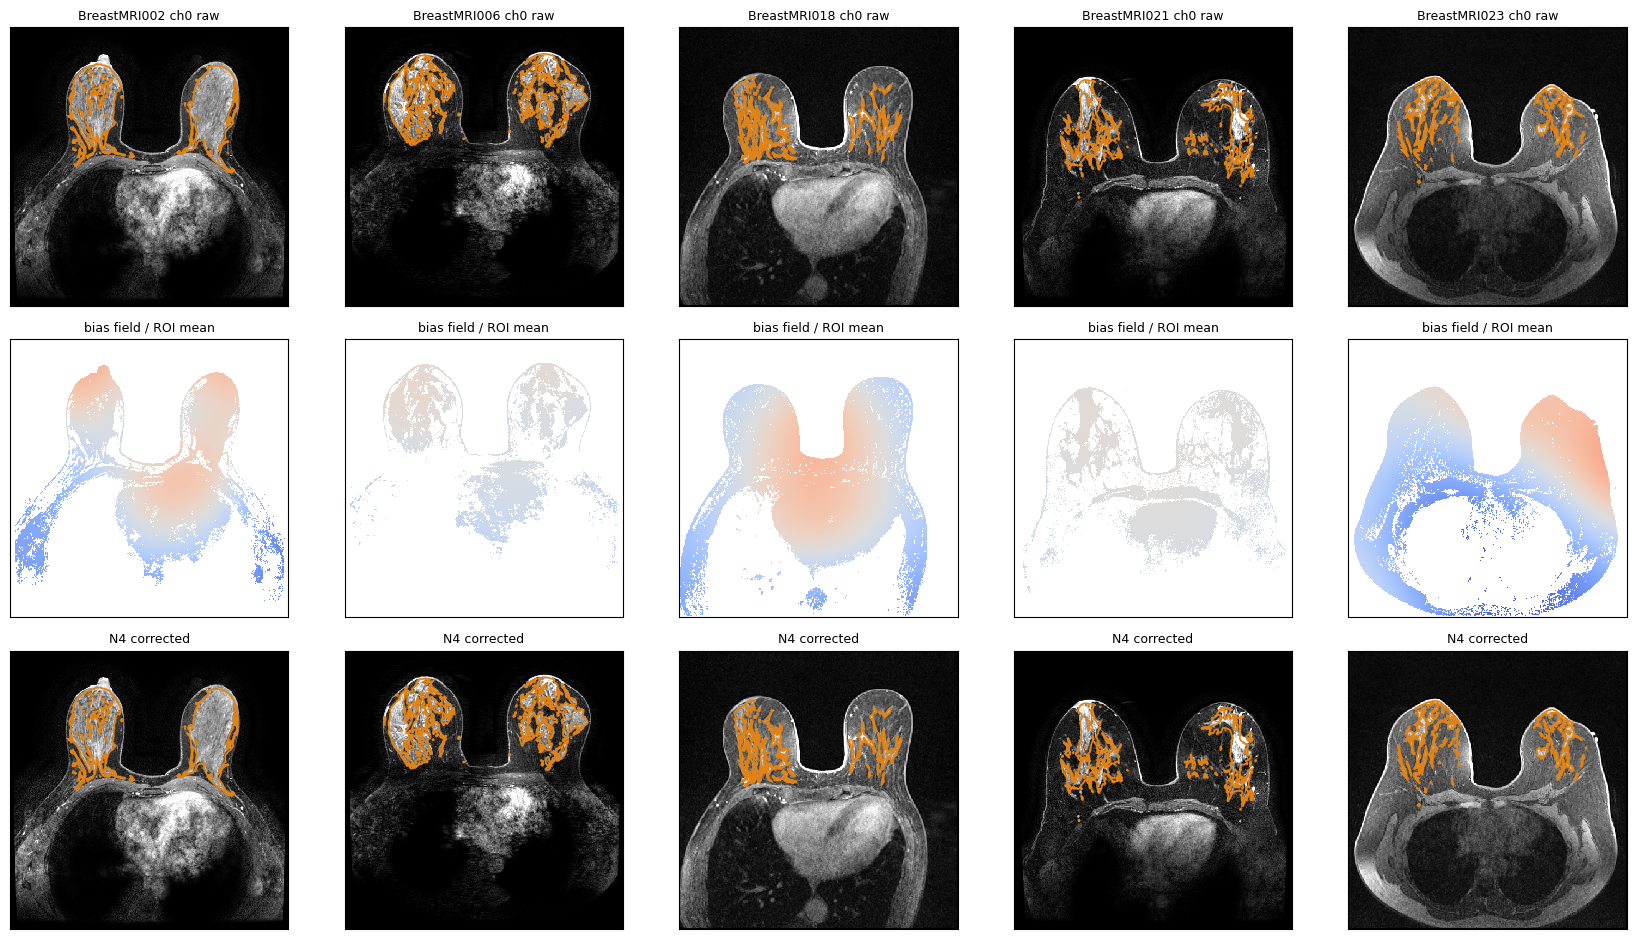

In [7]:
fig, axes = plt.subplots(3, len(list_case()), figsize=(17, 9.5))
for col, case in enumerate(list_case()):
    raw = load_image(image_path(case, 0))
    raw_arr = array_from_image(raw).astype(float)
    field = bias_examples[case]
    corrected = raw_arr / field
    sp = spacing_zyx(raw)
    roi = (array_from_image(load_image(mask_path(case, "L"))) > 0) | (array_from_image(load_image(mask_path(case, "R"))) > 0)
    z = largest_slice_index(roi, 0)
    show_image_with_mask(axes[0, col], raw_arr, roi, sp, 0, z, title=f"{case} ch0 raw", color="#e08214")
    body = array_from_image(body_mask(raw)) > 0
    field_display = np.where(body, field / field[roi].mean(), np.nan)
    show_image_with_mask(axes[1, col], field_display, None, sp, 0, z, title="bias field / ROI mean",
                         window=(0.7, 1.3), cmap="coolwarm")
    show_image_with_mask(axes[2, col], corrected, roi, sp, 0, z, title="N4 corrected", color="#e08214")
fig.tight_layout()
fig.savefig(Path(config["FIGURE_DIR"]) / "bias_fields.png", dpi=100)
plt.show()